\
# 03 · Длинные волны в бассейне: разнесённая сетка и вычислительная дисперсия

**Моделирование океана · лабораторная №2, вариант 11** *(постановка «Г»:
левая граница — твердая стенка, $h = 100$ м, $A = 2$ м, $T = 60$ мин)*

Линейные уравнения мелкой воды на сетке с разнесёнными узлами: расход $Q$
определён на **границах** ячеек, возвышение уровня $\eta$ — в **центрах**:

$$
\frac{\partial Q}{\partial t} = -g h \frac{\partial \eta}{\partial x}, \qquad
\frac{\partial \eta}{\partial t} = -\frac{\partial Q}{\partial x},
\qquad C = \sqrt{gh},\ \ \lambda = T\,C
$$

Разностная схема «вперёд-назад» (первый порядок, устойчива при CFL = $C\,\Delta t/\Delta x \le 1$):

$$
Q_j^{k+1} = Q_j^{k} - \frac{g h\,\Delta t}{\Delta x}\,(\eta_j^{k} - \eta_{j-1}^{k}), \qquad
\eta_i^{k+1} = \eta_i^{k} - \frac{\Delta t}{\Delta x}\,(Q_{i+1}^{k+1} - Q_i^{k+1})
$$

```
   Q-узлы:   Q0      Q1      Q2  ...            (границы ячеек)
   ячейки:     [ eta0 | eta1 | eta2 | ... ]    (центры ячеек)
   x = 0  — твердая стенка (Q0 = 0)
   x = L  — открытая граница (задаётся внешний уровень) или стенка
```

Два эксперимента: **входящая волна** (один период синусоиды входит через
открытую границу и отражается от стенки) и **начальное возвышение**
(купол $\eta$ распадается на две волны — сейшевые колебания замкнутого
бассейна). На разнесённой схеме численная (вычислительная) дисперсия
искажает форму пакета — её мерой служит $|1 - \max|\eta|/A|$.

In [1]:
\
from pathlib import Path
import sys

ROOT = Path.cwd().parent
if str(ROOT / "src") not in sys.path:  # если пакет oahm не установлен
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
})

FIG_DIR = ROOT / "figures"   # статичные иллюстрации для README
RES_DIR = ROOT / "results"   # анимации и обработанные данные
DATA_DIR = ROOT / "data"
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)


In [2]:
\
import oahm.long_wave as lw
from IPython.display import HTML

variants = pd.read_excel(DATA_DIR / "raw" / "wave_task_variants_2024.xlsx",
                         index_col=0, header=1)
variants.loc[[11]]

,"Постановка задачи (стр. 129, рис. 4.6, Практикум по динамике океана)","L1, км","L2, км","h1, м","h2, м","l, км","А, м","T, мин"
№ варианта,,,,,,,,
11,Г (левая граница-твердая стенка),NaN,NaN,100,NaN,NaN,2,60.0


In [3]:
\
var = variants.loc[11]
h = float(var["h1, м"])          # глубина, м
A = float(var["А, м"])           # амплитуда волны, м
T = float(var["T, мин"]) * 60    # период, с

C = np.sqrt(9.81 * h)            # фазовая скорость, м/с
lam = T * C                      # длина волны, м
L = 10 * lam                     # бассейн = 10 длин волн (постановка «Г»)

print(f"C = {C:.1f} м/с, lambda = {lam/1000:.1f} км, L = {L/1000:.1f} км")
print(f"время выхода волны к стенке: {L/C/3600:.1f} ч")

C = 31.3 м/с, lambda = 112.8 км, L = 1127.6 км
время выхода волны к стенке: 10.0 ч


\
## Эксперимент 1 — входящая волна

Пакет из одного периода заходит через открытую границу $x = L$, идёт к
твердой стенке $x=0$ и отражается. Снимки ниже — мгновенные профили уровня;
под ними — рост ошибки амплитуды $|1-\max|\eta|/A|$: до подхода к стенке она
растёт как следствие вычислительной дисперсии, в момент интерференции с
отражённой волной — скачок (это уже физика суперпозиции, а не численный
артефакт).

ячеек: 400, шагов: 1200, dx = 2819 м, dt = 45 с, CFL = 0.50


(<Figure size 1100x550 with 1 Axes>,
 <Axes: title={'center': 'Входящая волна: профили уровня в разные моменты'}, xlabel='Расстояние от твердой стенки, км', ylabel='Отклонение уровня, м'>)

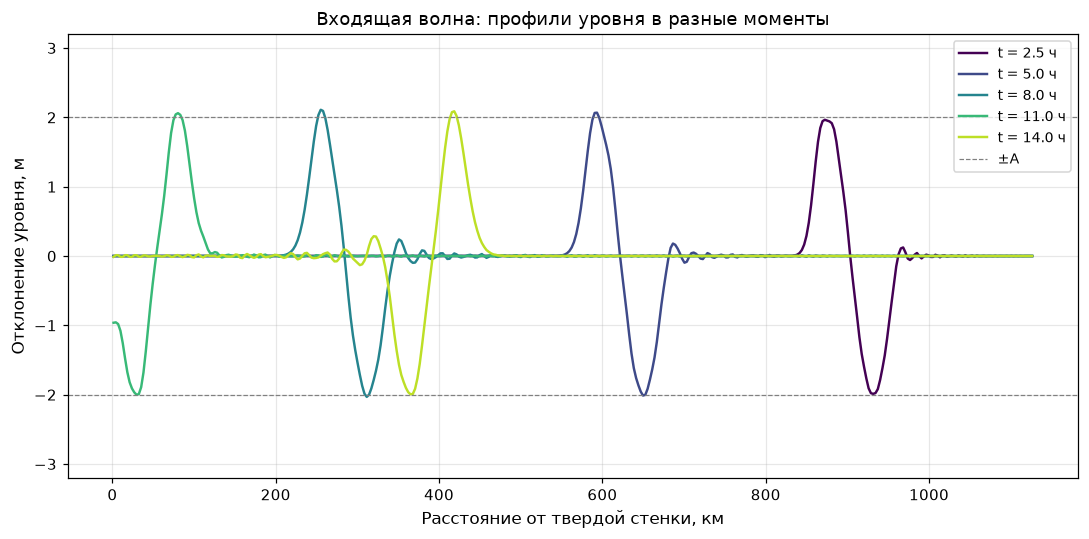

In [4]:
\
exp1 = lw.simulate_incoming_wave(L=L, h=h, A=A, T=T,
                                 duration_s=15 * 3600,
                                 cells_per_wavelength=40, CFL=0.5)
print(f"ячеек: {exp1.eta.shape[1]}, шагов: {exp1.eta.shape[0]-1}, "
      f"dx = {exp1.dx:.0f} м, dt = {exp1.dt:.0f} с, CFL = {exp1.cfl:.2f}")

hours = exp1.t / 3600
snapshots = [2.5, 5.0, 8.0, 11.0, 14.0]
steps = [int(s * 3600 / exp1.dt) for s in snapshots]
lw.snapshot_plot(exp1, steps,
                 title="Входящая волна: профили уровня в разные моменты",
                 path=FIG_DIR / "03_incoming_wave_snapshots.png")

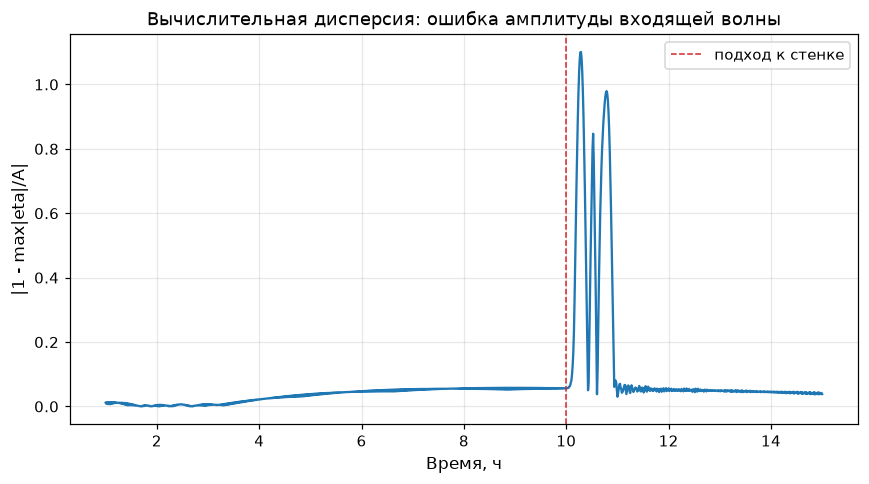

In [5]:
\
t_wall = L / C  # волна достигает стенки

fig, ax = plt.subplots(figsize=(8, 4.5))
# кривая с момента, когда пакет полностью вошёл в бассейн (t >= T):
# на нулевом шаге метрика даёт фиктивный скачок |1 - 0/A| = 1
entered = hours >= T / 3600
ax.plot(hours[entered], exp1.amplitude_error[entered], lw=1.5)
ax.axvline(t_wall / 3600, color="tab:red", ls="--", lw=1,
           label="подход к стенке")
ax.set_xlabel("Время, ч")
ax.set_ylabel("|1 - max|eta|/A|")
ax.set_title("Вычислительная дисперсия: ошибка амплитуды входящей волны")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_incoming_wave_dispersion.png", dpi=150,
            bbox_inches="tight")

In [6]:
\
lw.animate(exp1, RES_DIR / "03_incoming_wave.gif", fps=15, n_frames=180,
           title="Входящая волна (вариант 11)")
HTML('<img src="../results/03_incoming_wave.gif" width="820">')

\
## Эксперимент 2 — начальное возвышение (сейша)

В центре замкнутого бассейна задан купол $\eta$ длиной $\lambda/2$ и
амплитудой $A$. Купол распадается на две волны, которые отражаются от
стенок; в бассейне устанавливаются сейшевые колебания.

(<Figure size 1100x550 with 1 Axes>,
 <Axes: title={'center': 'Начальное возвышение: распад купола и сейша'}, xlabel='Расстояние от твердой стенки, км', ylabel='Отклонение уровня, м'>)

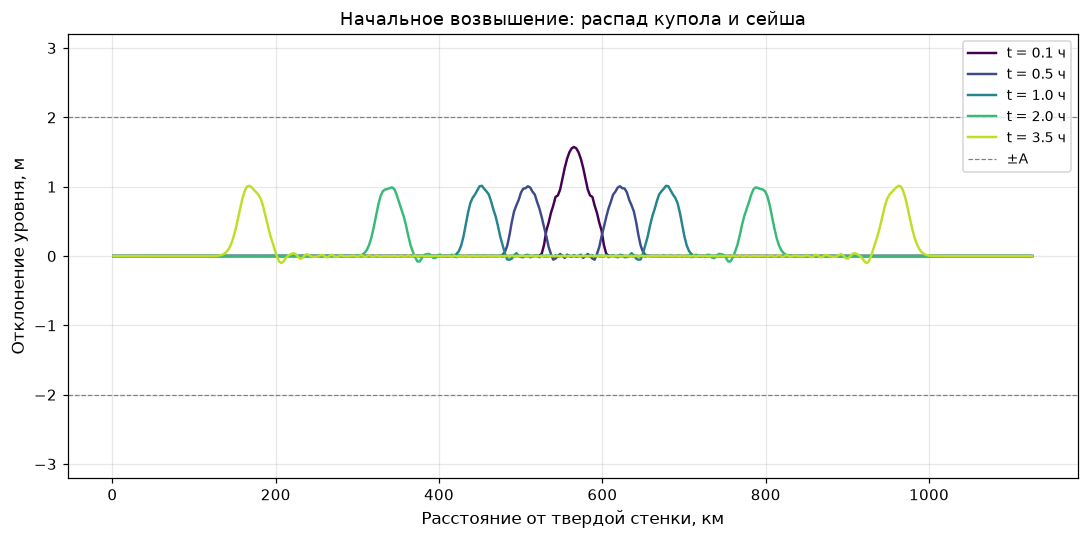

In [7]:
\
exp2 = lw.simulate_initial_elevation(L=L, h=h, A=A, T=T,
                                     duration_s=3.75 * 3600,
                                     cells_per_wavelength=40, CFL=0.5)

steps2 = [int(s * 3600 / exp2.dt) for s in (0.1, 0.5, 1.0, 2.0, 3.5)]
lw.snapshot_plot(exp2, steps2,
                 title="Начальное возвышение: распад купола и сейша",
                 path=FIG_DIR / "03_seiche_snapshots.png")

In [8]:
\
lw.animate(exp2, RES_DIR / "03_seiche.gif", fps=15, n_frames=140,
           title="Начальное возвышение → сейша (вариант 11)")
HTML('<img src="../results/03_seiche.gif" width="820">')

\
## Сходимость: разрешение против вычислительной дисперсии

Численная дисперсия схемы управляется отношением $\Delta x/\lambda$. Повторим
эксперимент 1 с разным разрешением и сравним максимальную ошибку амплитуды
**до** подхода волны к стенке (чистый численный эффект, без суперпозиции с
отражённой волной):

In [9]:
\
rows = []
for cpw in (8, 16, 40, 80):
    e = lw.simulate_incoming_wave(L=L, h=h, A=A, T=T,
                                  duration_s=15 * 3600,
                                  cells_per_wavelength=cpw, CFL=0.5)
    # окно строго до подхода пакета к стенке (без суперпозиции с отражением)
    clean = (e.t >= T) & (e.t < 0.8 * t_wall)  # пакет вошёл, до стенки далеко
    rows.append({
        "ячеек на длину волны": cpw,
        "dx, м": e.dx,
        "dt, с": e.dt,
        "max|1-An/A|": e.amplitude_error[clean].max(),
    })

res_study = pd.DataFrame(rows)
res_study.round(4)

,ячеек на длину волны,"dx, м","dt, с",max|1-An/A|
0,8,14094.4138,225.0,0.1188
1,16,7047.2069,112.5,0.0522
2,40,2818.8828,45.0,0.0563
3,80,1409.4414,22.5,0.0143


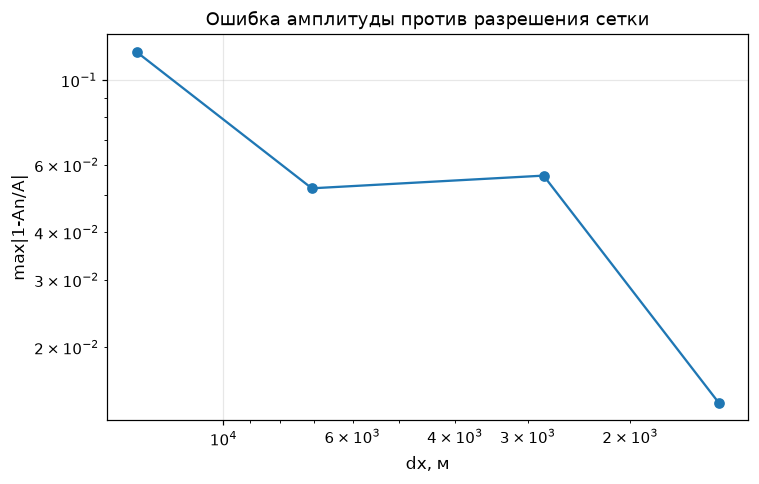

In [10]:
\
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(res_study["dx, м"], res_study["max|1-An/A|"], "o-")
ax.set_xlabel("dx, м")
ax.set_ylabel("max|1-An/A|")
ax.set_title("Ошибка амплитуды против разрешения сетки")
ax.invert_xaxis()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_resolution_study.png", dpi=150, bbox_inches="tight")

\
## Выводы

1. Реализована разнесённая (C-сетка) схема для линейных уравнений мелкой
   воды с условиями «твердая стенка» и «заданный внешний уровень»; шаг
   выбирается из условия Куранта (CFL = 0.5).
2. Анимации показывают физически согласованную картину: пакет длиной $\lambda$
   идёт к стенке со скоростью $\sqrt{gh} \approx 31$ м/с и отражается; купол
   в замкнутом бассейне порождает сейшу.
3. Вычислительная дисперсия даёт ошибку амплитуды ~12% при 8 ячейках на
   волну и ~1.4% при 80 — на порядок меньше (рабочее разрешение
   40 ячеек/$\lambda$ держит ошибку в пределах ~6%). Модель сходится
   с ростом разрешения, что и позволяет ей доверять.